In [58]:
from cell_explorer import CellExplorer

EBR = r"D:\data-distance-coding-project\mini2p-data\LDR004\ebr_pipeline_251204_LDR_LDR004_ltdk_10.pkl"
explorer = CellExplorer(EBR)

%load_ext autoreload
%autoreload 2

c:\Users\acostamendoza\projects\distance-project\mini2p-analysis\cell_explorer.py:28: UserWarning: This figure was saved with matplotlib version 3.9.2 and loaded with 3.9.4 so may not function correctly.
  ebr = pickle.load(f)


The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


c:\Users\acostamendoza\projects\distance-project\mini2p-analysis\ego_reformat.py:81: RuntimeWarning: invalid value encountered in cast
  occ = np.zeros((n_rays, n_dist))


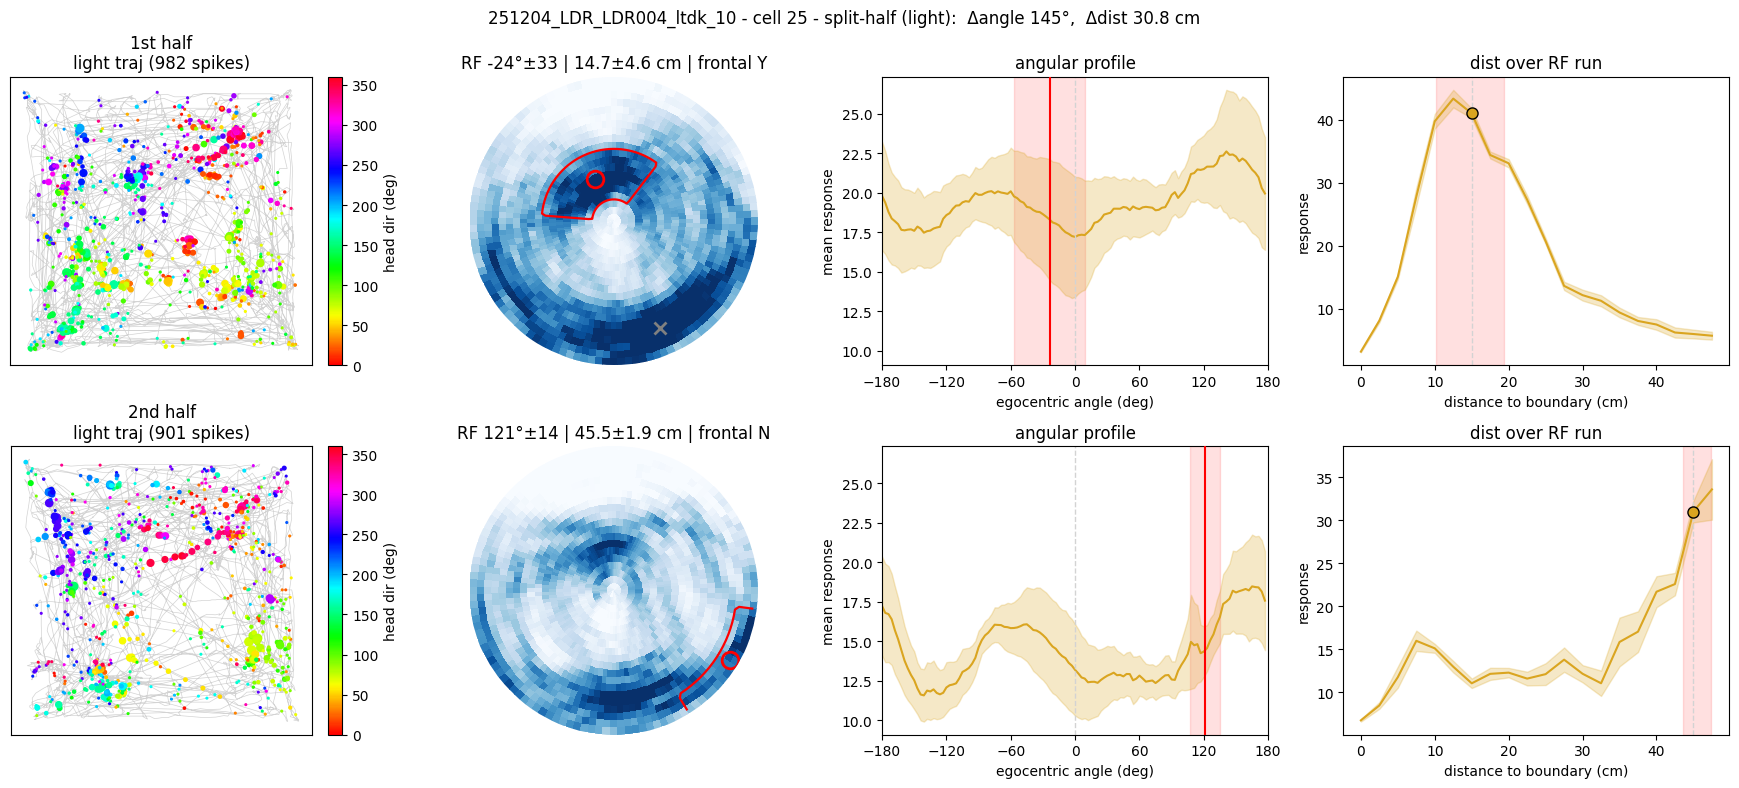

In [56]:
# any RFAnalyzer knob(s), one row each:
fig = ce.compare_rf(25, split_half=True)

c:\Users\acostamendoza\projects\distance-project\mini2p-analysis\ego_reformat.py:78: RuntimeWarning: invalid value encountered in cast
  bin_idx = np.floor(rd / bin_size).astype(int)


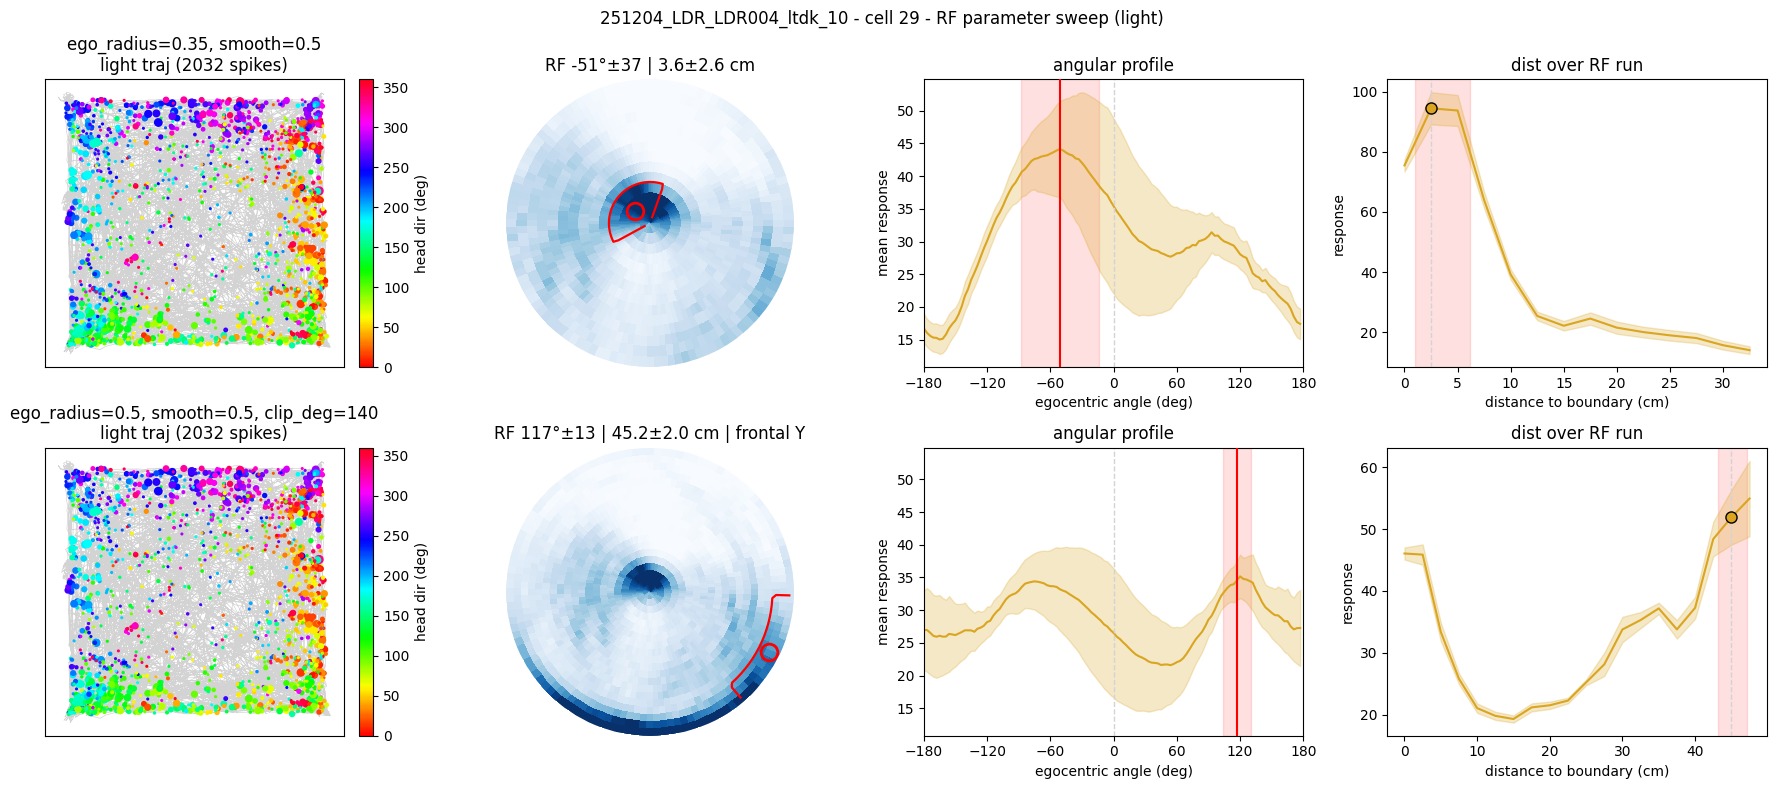

In [28]:
fig = ce.compare_rf(29, variants=[{"ego_radius": 0.35, "smooth": 0.5}, {"ego_radius": 0.5, "smooth":0.5, "clip_deg":140}])

In [136]:
# one-time setup (~90s): computes the per-cell reliability + shuffle nulls
from visual_cells import VisualClassifier
clf_2 = VisualClassifier(ce_2)
df_2 = clf_2.classify()            # run ONCE; plot_cell reuses these results

[VisualClassifier] 251122_LDR_LDR004_ltdk_17 -- 421 cells
  params: percentile=99  min_light_corr=0.5  n_splits=40/126  n_shuffles=100
  light reliable (real > p99 null): 383   dark reliable: 197
  VISUAL (light-reliable & >=0.5 & dark-unreliable): 134  (31.8%)
  rejected of 383 light-reliable: 180 also dark-reliable, 69 below floor 0.5
  median reliability (real / p99 null):  light 0.58 / 0.17   dark 0.17 / 0.18


In [5]:
import numpy as np
from ego_reformat import compute_ego_maps

rd_all = np.stack(ce.df["ray_distances"].values)        # (F, n_rays), meters
print("max boundary distance:", np.nanmax(rd_all)*100, "cm",
      "| current ego_radius:", ce.settings["ego_radius"]*100, "cm")


max boundary distance: 73.7 cm | current ego_radius: 35.0 cm


In [1]:
from cell_explorer import CellExplorer

EBR = r"D:\data-distance-coding-project\mini2p-data\LDR004\ebr_pipeline_251204_LDR_LDR004_ltdk_10.pkl"
ce = CellExplorer(EBR)
                          # or fig.savefig(...)

c:\Users\acostamendoza\projects\distance-project\mini2p-analysis\cell_explorer.py:28: UserWarning: This figure was saved with matplotlib version 3.9.2 and loaded with 3.9.4 so may not function correctly.
  ebr = pickle.load(f)


In [37]:
import importlib, receptive_field; importlib.reload(receptive_field)   # if already imported
from receptive_field import RFAnalyzer

# one-time setup (~90s): computes the per-cell reliability + shuffle nulls
from visual_cells import VisualClassifier

clf = VisualClassifier(ce)

rf = RFAnalyzer(ce, clf)        # reuses ce arrays + clf's is_visual subset
df = rf.table()              # one row per visual cell: RF center + size
# fig = rf.plot_cell(2)                 # ego map + RF center/outline | angular | distance profile
rf.plot_population(df)       # population RF map + angle rose + distance histogram
# rf.rf(2)                        # single-cell dict (no plotting): rf_angle_deg, rf_dist_cm, ...


ValueError: no visual subset available -- pass a classified VisualClassifier, or call with an explicit `cells` list

In [38]:
rf.plot_cell(27)   

c:\Users\acostamendoza\projects\distance-project\mini2p-analysis\ego_reformat.py:78: RuntimeWarning: invalid value encountered in cast
  bin_idx = np.floor(rd / bin_size).astype(int)


AttributeError: 'RFAnalyzer' object has no attribute 'fov'

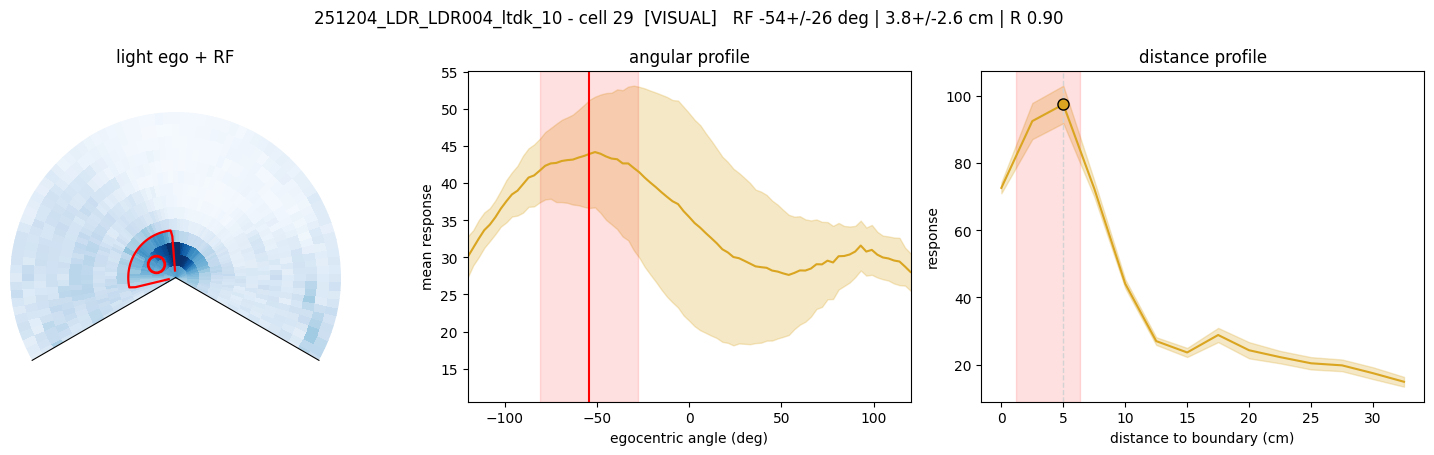

In [132]:
rf.plot_cell(29)  

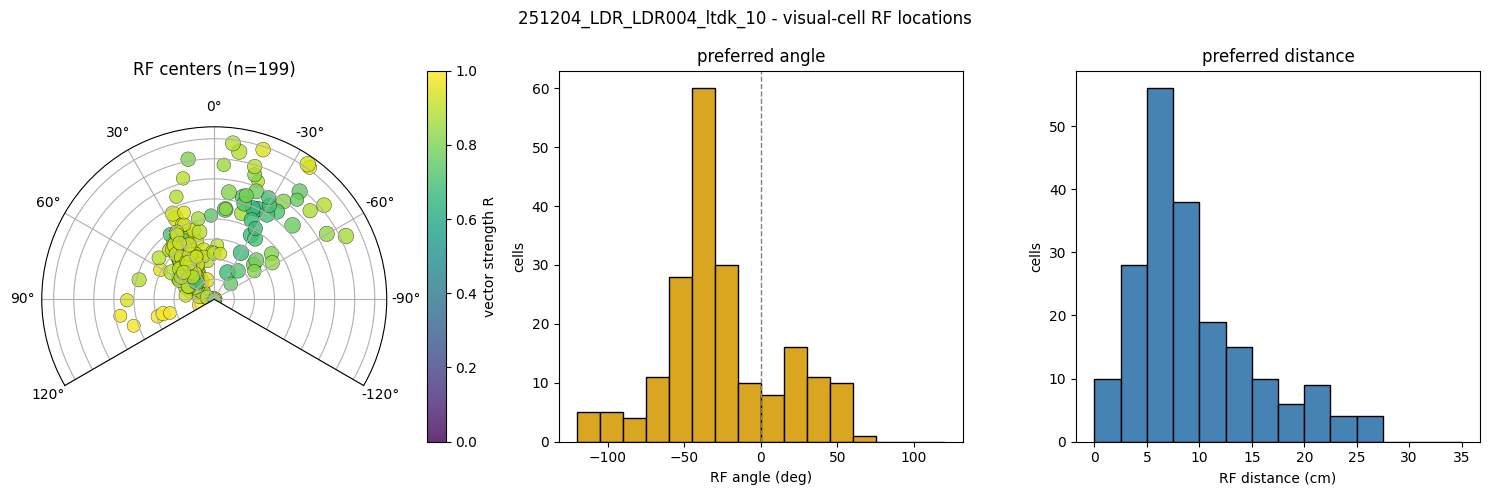

In [107]:
rf.plot_population(df_rf)

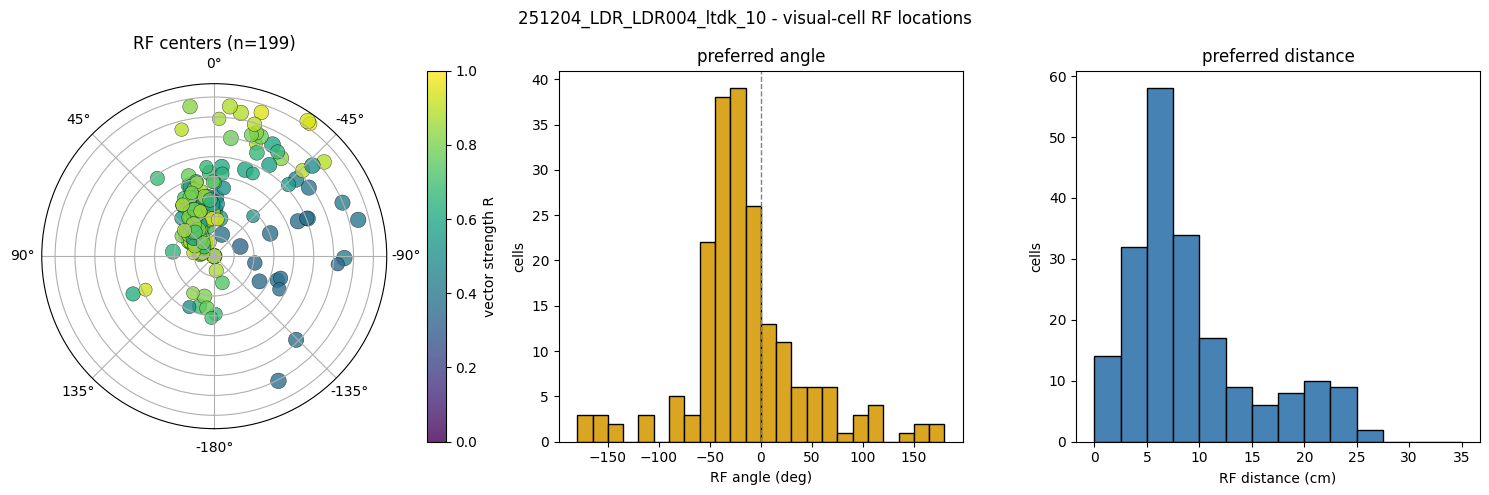

In [134]:
rf.plot_population(df_rf)

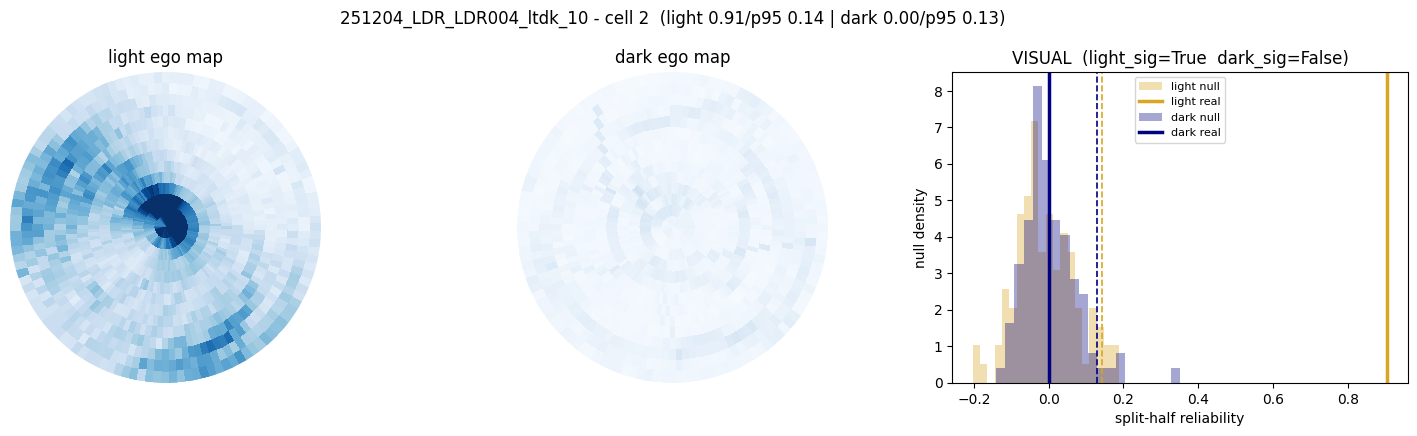

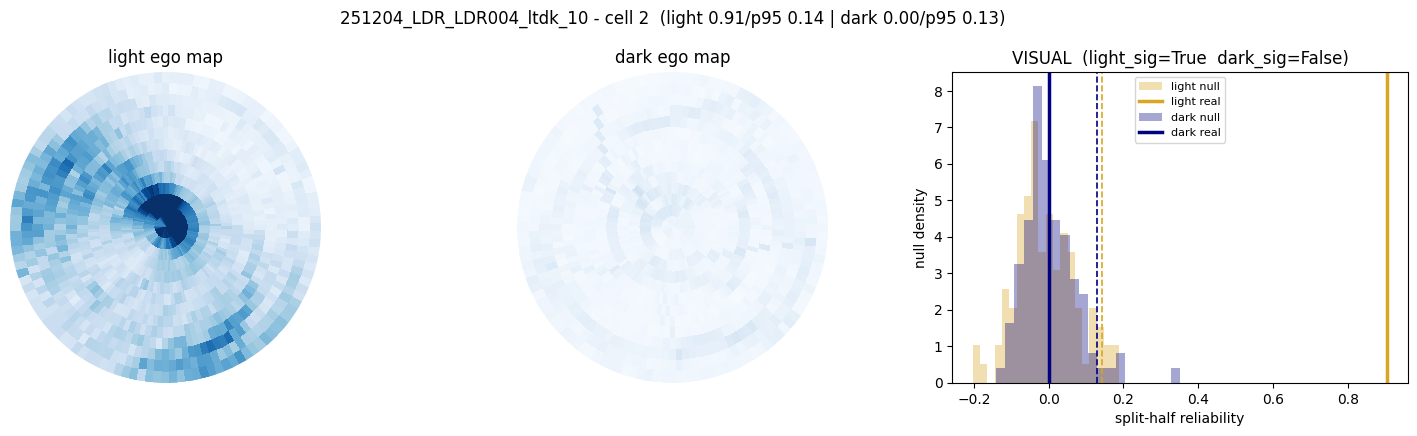

In [35]:
from visual_cells import VisualClassifier
clf = VisualClassifier(ce)          # reuses the loaded session; ~90 s
df  = clf.classify()                # per-cell table; is_visual is the verdict
df[df.is_visual]                    # the visual cells
clf.plot_cell(2)                    # inspect: light map | dark map | reliability vs null

In [57]:
"""Plot RFAnalyzer.plot_population for every LDR004 session.
Saves results/LDR004_ltdk_<NN>/rf_population.png (+ rf_table.csv) per session."""
import os, re, glob, time, sys
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt

sys.path.insert(0, r"c:\Users\acostamendoza\projects\distance-project\mini2p-analysis")
from cell_explorer import CellExplorer
from visual_cells import VisualClassifier
from receptive_field import RFAnalyzer

DATA = r"D:\data-distance-coding-project\mini2p-data\DMM065"
RESULTS = os.path.join(DATA, "results")

pkls = sorted(glob.glob(os.path.join(DATA, "ebr_pipeline_*.pkl")))
print(f"{len(pkls)} sessions", flush=True)

t_all = time.time()
for i, pkl in enumerate(pkls, 1):
    name = os.path.basename(pkl)
    m = re.search(r"ltdk_(\w+)\.pkl$", name)
    if not m:
        print(f"[{i}/{len(pkls)}] SKIP (no ltdk token): {name}", flush=True)
        continue
    tok = m.group(1)
    out_dir = os.path.join(RESULTS, f"DMM065_ltdk_{tok}")
    os.makedirs(out_dir, exist_ok=True)
    t0 = time.time()
    try:
        ce = CellExplorer(pkl)
        clf = VisualClassifier(ce)
        clf.classify(verbose=False)
        rf = RFAnalyzer(ce, clf)              # full-range RF (clip_deg=None)
        df = rf.table()
        fig = rf.plot_population(df)
        fig.savefig(os.path.join(out_dir, "rf_population.png"), dpi=120, bbox_inches="tight")
        plt.close(fig)
        df.to_csv(os.path.join(out_dir, "rf_table.csv"), index=False)   # bonus: per-cell RF
        print(f"[{i}/{len(pkls)}] ltdk_{tok}: {len(df)} visual cells -> {out_dir}  "
              f"({time.time()-t0:.0f}s)", flush=True)
    except Exception as e:
        plt.close("all")
        print(f"[{i}/{len(pkls)}] ltdk_{tok} FAILED: {type(e).__name__}: {e}", flush=True)

print(f"\nDONE {len(pkls)} sessions in {(time.time()-t_all)/60:.1f} min", flush=True)


25 sessions


c:\Users\acostamendoza\projects\distance-project\mini2p-analysis\cell_explorer.py:28: UserWarning: This figure was saved with matplotlib version 3.9.2 and loaded with 3.9.4 so may not function correctly.
  ebr = pickle.load(f)
c:\Users\acostamendoza\projects\distance-project\mini2p-analysis\ego_reformat.py:81: RuntimeWarning: invalid value encountered in cast
  occ = np.zeros((n_rays, n_dist))


[1/25] ltdk_03: 16 visual cells -> D:\data-distance-coding-project\mini2p-data\DMM065\results\DMM065_ltdk_03  (47s)


c:\Users\acostamendoza\projects\distance-project\mini2p-analysis\cell_explorer.py:28: UserWarning: This figure was saved with matplotlib version 3.9.2 and loaded with 3.9.4 so may not function correctly.
  ebr = pickle.load(f)
c:\Users\acostamendoza\projects\distance-project\mini2p-analysis\ego_reformat.py:81: RuntimeWarning: invalid value encountered in cast
  occ = np.zeros((n_rays, n_dist))


[2/25] ltdk_02: 21 visual cells -> D:\data-distance-coding-project\mini2p-data\DMM065\results\DMM065_ltdk_02  (48s)


...

[23/25] ltdk_21: 113 visual cells -> D:\data-distance-coding-project\mini2p-data\DMM065\results\DMM065_ltdk_21  (124s)


c:\Users\acostamendoza\projects\distance-project\mini2p-analysis\cell_explorer.py:28: UserWarning: This figure was saved with matplotlib version 3.9.2 and loaded with 3.9.4 so may not function correctly.
  ebr = pickle.load(f)
c:\Users\acostamendoza\projects\distance-project\mini2p-analysis\ego_reformat.py:81: RuntimeWarning: invalid value encountered in cast
  occ = np.zeros((n_rays, n_dist))


[24/25] ltdk_22: 257 visual cells -> D:\data-distance-coding-project\mini2p-data\DMM065\results\DMM065_ltdk_22  (139s)


c:\Users\acostamendoza\projects\distance-project\mini2p-analysis\cell_explorer.py:28: UserWarning: This figure was saved with matplotlib version 3.9.2 and loaded with 3.9.4 so may not function correctly.
  ebr = pickle.load(f)
c:\Users\acostamendoza\projects\distance-project\mini2p-analysis\ego_reformat.py:81: RuntimeWarning: invalid value encountered in cast
  occ = np.zeros((n_rays, n_dist))


[25/25] ltdk_06: 109 visual cells -> D:\data-distance-coding-project\mini2p-data\DMM065\results\DMM065_ltdk_06  (95s)

DONE 25 sessions in 31.7 min


In [4]:
"""Per-cell PDFs (visual / non-visual) with the robust RF overlaid on ce.plot_cell, for every
LDR004 session.  results/LDR004_ltdk_<NN>/{visual,non_visual}/<group>.pdf  (1 page per cell)."""
import os, re, io, glob, time, sys
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from matplotlib.backends.backend_pdf import PdfPages

sys.path.insert(0, r"c:\Users\acostamendoza\projects\distance-project\mini2p-analysis")
from cell_explorer import CellExplorer
from visual_cells import VisualClassifier
from receptive_field import RFAnalyzer

DATA    = r"D:\data-distance-coding-project\mini2p-data\LDR004"
RESULTS = os.path.join(DATA, "results")
DPI         = 80                      # lower -> smaller/faster PDFs
GROUPS      = ("visual", "non_visual")  # set to ("visual",) to skip non-visual
ONLY_TOKENS = None                    # e.g. {"10"} to run one session
MAX_CELLS   = None                   # e.g. 5 for a quick smoke test per group


def fig_to_pdf_page(pdf, fig):
    """Rasterize a figure onto one PDF page (keeps PDFs small despite the trajectory scatters)."""
    buf = io.BytesIO()
    fig.savefig(buf, format="png", dpi=DPI, bbox_inches="tight")
    plt.close(fig); buf.seek(0)
    im = plt.imread(buf); h, w = im.shape[:2]
    pg = plt.figure(figsize=(16, 16 * h / w))
    ax = pg.add_axes([0, 0, 1, 1]); ax.imshow(im); ax.axis("off")
    pdf.savefig(pg, dpi=DPI); plt.close(pg)


pkls = sorted(glob.glob(os.path.join(DATA, "ebr_pipeline_*.pkl")))
print(f"{len(pkls)} sessions found", flush=True)

t_all = time.time()
for si, pkl in enumerate(pkls, 1):
    m = re.search(r"ltdk_(\w+)\.pkl$", os.path.basename(pkl))
    if not m:
        continue
    tok = m.group(1)
    if ONLY_TOKENS and tok not in ONLY_TOKENS:
        continue
    out_base = os.path.join(RESULTS, f"LDR004_ltdk_{tok}")
    t0 = time.time()
    try:
        ce = CellExplorer(pkl)
        clf = VisualClassifier(ce); clf.classify(verbose=False)
        rf = RFAnalyzer(ce, clf)
        df = clf._last["df"]
        groups = {"visual": df[df.is_visual].cell.tolist(),
                  "non_visual": df[~df.is_visual].cell.tolist()}
    except Exception as e:
        plt.close("all")
        print(f"[{si}/{len(pkls)}] ltdk_{tok} CLASSIFY FAILED: {type(e).__name__}: {e}", flush=True)
        continue

    print(f"[{si}/{len(pkls)}] ltdk_{tok}: {len(groups['visual'])} visual / "
          f"{len(groups['non_visual'])} non-visual  (classify {time.time()-t0:.0f}s)", flush=True)

    for gname in GROUPS:
        cells = groups[gname][:MAX_CELLS] if MAX_CELLS else groups[gname]
        folder = os.path.join(out_base, gname); os.makedirs(folder, exist_ok=True)
        pdf_path = os.path.join(folder, f"{gname}.pdf")
        with PdfPages(pdf_path) as pdf:
            for i, cid in enumerate(cells):
                try:
                    fig_to_pdf_page(pdf, rf.plot_cell_full(int(cid)))
                except Exception as e:
                    plt.close("all")
                    print(f"    !! {gname} cell {cid}: {type(e).__name__}: {e}", flush=True)
                if (i + 1) % 50 == 0 or i + 1 == len(cells):
                    print(f"    {gname} {i+1}/{len(cells)}  ({time.time()-t0:.0f}s)", flush=True)
        print(f"    -> {pdf_path}", flush=True)

print(f"\nDONE in {(time.time()-t_all)/60:.1f} min", flush=True)

24 sessions found


c:\Users\acostamendoza\projects\distance-project\mini2p-analysis\cell_explorer.py:28: UserWarning: This figure was saved with matplotlib version 3.9.2 and loaded with 3.9.4 so may not function correctly.
  ebr = pickle.load(f)


[1/24] ltdk_03: 15 visual / 248 non-visual  (classify 48s)


c:\Users\acostamendoza\projects\distance-project\mini2p-analysis\ego_reformat.py:76: RuntimeWarning: invalid value encountered in cast
  bin_idx = np.floor(rd / bin_size).astype(int)


    visual 15/15  (60s)
    -> D:\data-distance-coding-project\mini2p-data\LDR004\results\LDR004_ltdk_03\visual\visual.pdf
    non_visual 50/248  (85s)
    non_visual 100/248  (110s)
    non_visual 150/248  (135s)
    non_visual 200/248  (159s)
    non_visual 248/248  (183s)
    -> D:\data-distance-coding-project\mini2p-data\LDR004\results\LDR004_ltdk_03\non_visual\non_visual.pdf


...

    visual 50/74  (89s)
    visual 74/74  (101s)
    -> D:\data-distance-coding-project\mini2p-data\LDR004\results\LDR004_ltdk_22\visual\visual.pdf
    non_visual 50/240  (128s)
    non_visual 100/240  (153s)
    non_visual 150/240  (178s)
    non_visual 200/240  (203s)
    non_visual 240/240  (223s)
    -> D:\data-distance-coding-project\mini2p-data\LDR004\results\LDR004_ltdk_22\non_visual\non_visual.pdf


c:\Users\acostamendoza\projects\distance-project\mini2p-analysis\cell_explorer.py:28: UserWarning: This figure was saved with matplotlib version 3.9.2 and loaded with 3.9.4 so may not function correctly.
  ebr = pickle.load(f)


[24/24] ltdk_21: 64 visual / 236 non-visual  (classify 56s)


c:\Users\acostamendoza\projects\distance-project\mini2p-analysis\ego_reformat.py:76: RuntimeWarning: invalid value encountered in cast
  bin_idx = np.floor(rd / bin_size).astype(int)


    visual 50/64  (86s)
    visual 64/64  (93s)
    -> D:\data-distance-coding-project\mini2p-data\LDR004\results\LDR004_ltdk_21\visual\visual.pdf
    non_visual 50/236  (119s)
    non_visual 100/236  (144s)
    non_visual 150/236  (169s)
    non_visual 200/236  (195s)
    non_visual 236/236  (212s)
    -> D:\data-distance-coding-project\mini2p-data\LDR004\results\LDR004_ltdk_21\non_visual\non_visual.pdf

DONE in 145.5 min


In [51]:
"""Per-cell PDF pages: CellExplorer plot + VisualClassifier plot, one page each,
split into visual / non_visual folders under results."""
import os, io, sys, time
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from matplotlib.backends.backend_pdf import PdfPages

sys.path.insert(0, r"c:\Users\acostamendoza\projects\distance-project\mini2p-analysis")
from cell_explorer import CellExplorer
from visual_cells import VisualClassifier

EBR = r"D:\data-distance-coding-project\mini2p-data\LDR004\ebr_pipeline_251122_LDR_LDR004_ltdk_17.pkl"
OUT = r"D:\data-distance-coding-project\mini2p-data\LDR004\results\LDR004_ltdk_17"

print("loading + classifying...", flush=True)
ce = CellExplorer(EBR)
clf = VisualClassifier(ce)
df = clf.classify(seed=0)                      # populates clf._last for plot_cell
groups = {
    "visual":     df[df.is_visual].cell.tolist(),
    "non_visual": df[~df.is_visual].cell.tolist(),
}
print({k: len(v) for k, v in groups.items()}, flush=True)


def _png(fig, dpi=120):
    buf = io.BytesIO()
    fig.savefig(buf, format="png", dpi=dpi, bbox_inches="tight")
    plt.close(fig); buf.seek(0)
    return plt.imread(buf)


def render_page(pdf, cell):
    """One page: CellExplorer figure (top) + VisualClassifier figure (bottom)."""
    im1 = _png(ce.plot_cell(cell))             # 2x4 trajectory / ego / angular / distance
    im2 = _png(clf.plot_cell(cell))            # light/dark ego maps + reliability vs null
    (h1, w1), (h2, w2) = im1.shape[:2], im2.shape[:2]
    W = 15.0
    H1, H2 = W * h1 / w1, W * h2 / w2
    page = plt.figure(figsize=(W, H1 + H2))
    gs = page.add_gridspec(2, 1, height_ratios=[H1, H2], hspace=0.03)
    for ax, im in zip((page.add_subplot(gs[0]), page.add_subplot(gs[1])), (im1, im2)):
        ax.imshow(im); ax.axis("off")
    pdf.savefig(page, dpi=120); plt.close(page)


t0 = time.time()
for name, cells in groups.items():
    folder = os.path.join(OUT, name)
    os.makedirs(folder, exist_ok=True)
    pdf_path = os.path.join(folder, f"{name}.pdf")
    print(f"\n[{name}] {len(cells)} cells -> {pdf_path}", flush=True)
    with PdfPages(pdf_path) as pdf:
        for i, cid in enumerate(cells):
            try:
                render_page(pdf, cid)
            except Exception as e:
                print(f"  !! cell {cid} failed: {e}", flush=True)
                plt.close("all")
            if (i + 1) % 25 == 0 or i + 1 == len(cells):
                print(f"  {i+1}/{len(cells)}  ({time.time()-t0:.0f}s)", flush=True)

print(f"\nDONE in {time.time()-t0:.0f}s", flush=True)

loading + classifying...


c:\Users\acostamendoza\projects\distance-project\mini2p-analysis\cell_explorer.py:28: UserWarning: This figure was saved with matplotlib version 3.9.2 and loaded with 3.9.4 so may not function correctly.
  ebr = pickle.load(f)


{'visual': 139, 'non_visual': 282}

[visual] 139 cells -> D:\data-distance-coding-project\mini2p-data\LDR004\results\LDR004_ltdk_17\visual\visual.pdf


c:\Users\acostamendoza\projects\distance-project\mini2p-analysis\ego_reformat.py:76: RuntimeWarning: invalid value encountered in cast
  bin_idx = np.floor(rd / bin_size).astype(int)


  25/139  (28s)
  50/139  (50s)
  75/139  (72s)
  100/139  (94s)
  125/139  (116s)
  139/139  (128s)

[non_visual] 282 cells -> D:\data-distance-coding-project\mini2p-data\LDR004\results\LDR004_ltdk_17\non_visual\non_visual.pdf
  25/282  (154s)
  50/282  (176s)
  75/282  (197s)
  100/282  (217s)
  125/282  (239s)
  150/282  (260s)
  175/282  (281s)
  200/282  (303s)
  225/282  (325s)
  250/282  (347s)
  275/282  (369s)
  282/282  (376s)

DONE in 387s
